# Lab 1: Guided EDA of the breast cancer Wisconsin dataset

In this lab you run the exploratory-data-analysis checklist from episode 1.5 on a new dataset, without a tutor
typing ahead of you. The data are 569 breast tumours imaged by fine-needle aspiration; for each tumour, 30
numbers describe the cell nuclei in the image, and a pathologist's diagnosis (malignant or benign) is the label.
Chapter 2 uses this same table to train a classifier, so the picture you build here is one you will need again.

**Goals**

- Inspect a new table systematically: shape, types, missing values, class balance and summary statistics.
- Compare the distributions of several features between two classes with histograms, KDEs and box plots.
- Read a correlation heatmap and a pairplot and say which features are redundant and which separate the classes.
- Rank features by how well they separate the classes, and write a short, honest summary of what you found.

**How to work**

- Run the cells from top to bottom. Each task builds on the previous one.
- Cells that start with `# TODO` are yours to write. The comment line states the task.
- Cells marked ✅ are checks: they tell you whether you are on track. If one fails, read the message and fix the cell above it.
- You will not be asked to change anything that is not marked TODO.

In [1]:
# Setup: works locally and on Google Colab. Installs only what is missing.
import importlib.util

try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

REQUIRED = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib", "seaborn": "seaborn", "sklearn": "scikit-learn"}
missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if IN_COLAB and missing:
    %pip install -q {" ".join(missing)}

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("running on Colab" if IN_COLAB else "running locally", "| missing packages:", missing or "none")

running locally | missing packages: none


## The data

This dataset ships with scikit-learn, so there is nothing to download: `load_breast_cancer(as_frame=True)` returns
a pandas DataFrame with the 30 features and an integer `target` column (0 = malignant, 1 = benign). We add a
readable `diagnosis` column so that plots label themselves.

In [2]:
from sklearn.datasets import load_breast_cancer

bc = load_breast_cancer(as_frame=True)
df = bc.frame.assign(diagnosis=bc.frame["target"].map({0: "malignant", 1: "benign"}))
print(bc.target_names)  # index 0 -> malignant, index 1 -> benign
df.sample(5, random_state=42)

['malignant' 'benign']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,diagnosis
204,12.47,18.60,81.09,481.9,0.09965,0.1058,0.08005,0.03821,0.1925,0.06373,...,96.05,677.9,0.1426,0.2378,0.2671,0.10150,0.3014,0.08750,1,benign
70,18.94,21.31,123.60,1130.0,0.09009,0.1029,0.10800,0.07951,0.1582,0.05461,...,165.90,1866.0,0.1193,0.2336,0.2687,0.17890,0.2551,0.06589,0,malignant
131,15.46,19.48,101.70,748.9,0.10920,0.1223,0.14660,0.08087,0.1931,0.05796,...,124.90,1156.0,0.1546,0.2394,0.3791,0.15140,0.2837,0.08019,0,malignant
431,12.40,17.68,81.47,467.8,0.10540,0.1316,0.07741,0.02799,0.1811,0.07102,...,89.61,515.8,0.1450,0.2629,0.2403,0.07370,0.2556,0.09359,1,benign
540,11.54,14.44,74.65,402.9,0.09984,0.1120,0.06737,0.02594,0.1818,0.06782,...,78.78,457.8,0.1345,0.2118,0.1797,0.06918,0.2329,0.08134,1,benign


**Loading the course CSVs elsewhere.** Other labs read files from the course's `data/` folder (for example the
penguins). On your own machine those files sit next to the notebook or at the repository root; on Colab they do
not exist, so the helper below tries the local paths first and then falls back to the raw file on GitHub. You do
not need it for this lab, but run it once so that you recognise the pattern when it appears in Lab 2.

In [3]:
from pathlib import Path


def load_course_csv(name: str) -> pd.DataFrame:
    """Read a course CSV from the first location that exists: next to the notebook, at the repo root, or GitHub."""
    candidates = [
        Path("data") / name,
        Path("../../../data") / name,
        f"https://raw.githubusercontent.com/YOUR-USER/molecules-and-models/main/data/{name}",
    ]
    for candidate in candidates:
        if isinstance(candidate, str) or candidate.exists():
            return pd.read_csv(candidate)
    raise FileNotFoundError(name)


# Example (not needed below): penguins = load_course_csv("penguins.csv")
print("helper defined; first candidate path:", Path("data") / "penguins.csv")

helper defined; first candidate path: data\penguins.csv


## Task 1: shape, types and missing values

Start exactly as in episode 1.5: how big is the table, what type is each column, and is anything missing?
Store the number of missing values (over the whole table) in a variable called `n_missing`.

In [4]:
# Task 1: print df.shape, show df.dtypes, and compute n_missing = total number of missing values in df
print(df.shape)
print(df.dtypes.value_counts())
n_missing = int(df.isna().sum().sum())
print("missing values:", n_missing)

(569, 32)
float64    30
int64       1
str         1
Name: count, dtype: int64
missing values: 0


In [5]:
assert df.shape == (569, 32), "expected 569 rows and 32 columns (30 features + target + diagnosis)"
assert n_missing == 0, "this dataset has no missing values; check df.isna().sum().sum()"
print("✅ Task 1: 569 rows, 32 columns, no missing values")

✅ Task 1: 569 rows, 32 columns, no missing values


## Task 2: class balance

How many tumours of each class are there? Count them with `value_counts()` and store the result in `counts`,
then draw a bar chart of the counts with the object-oriented matplotlib API (`fig, ax = plt.subplots()`;
`ax.bar(...)`). Label the y axis.

diagnosis
benign       357
malignant    212
Name: count, dtype: int64


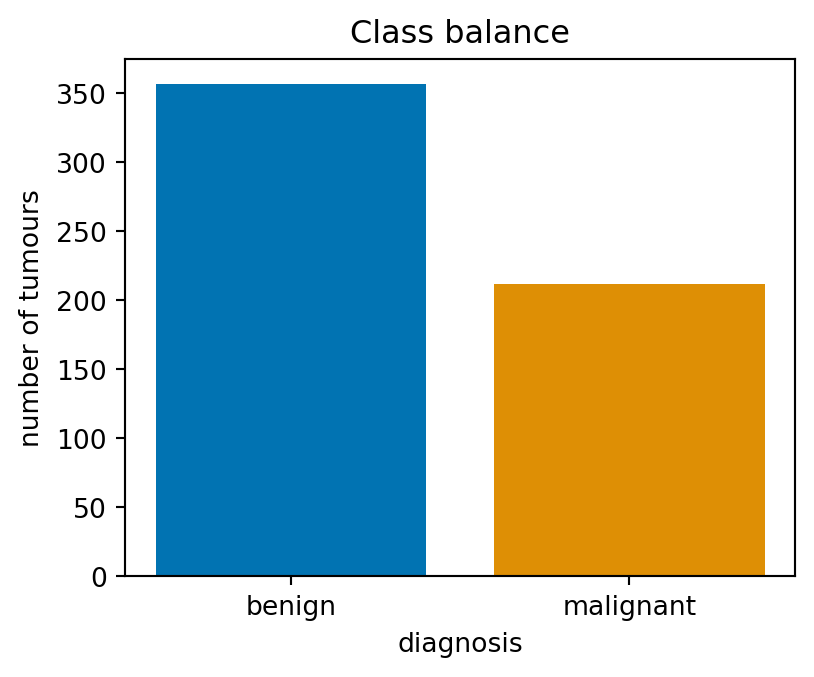

In [6]:
#| fig-alt: "Bar chart of the number of tumours per diagnosis: about 357 benign and 212 malignant."
# Task 2: counts = df["diagnosis"].value_counts(); then a bar chart of counts with labelled axes
counts = df["diagnosis"].value_counts()
print(counts)

fig, ax = plt.subplots(figsize=(4.5, 3.5))
ax.bar(counts.index, counts.values, color=sns.color_palette("colorblind")[:2])
ax.set(xlabel="diagnosis", ylabel="number of tumours", title="Class balance")
plt.show()

In [7]:
assert counts["benign"] == 357 and counts["malignant"] == 212, "expected 357 benign and 212 malignant"
print(f"✅ Task 2: {counts['malignant']} malignant, {counts['benign']} benign ({counts['benign'] / len(df):.0%} benign)")

✅ Task 2: 212 malignant, 357 benign (63% benign)


About 63% of the tumours are benign. Remember this number: in Chapter 2 a classifier that always says "benign"
will score 63% accuracy while missing every malignant case, which is why accuracy alone is never enough.

## Task 3: summary statistics

The 30 features come in three groups of ten: the `mean ...` of each nucleus measurement over the image, the
`... error` (standard error) and the `worst ...` (mean of the three largest values). Build a list `mean_features`
of the ten column names that start with `"mean "`, then show `describe()` for those columns, transposed so
that one row is one feature.

In [8]:
# Task 3: mean_features = the ten column names starting with "mean "; show df[mean_features].describe().T
mean_features = [c for c in df.columns if c.startswith("mean ")]
df[mean_features].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


In [9]:
assert len(mean_features) == 10, f"expected 10 'mean' features, got {len(mean_features)}"
assert all(c.startswith("mean ") for c in mean_features), "every name should start with 'mean '"
print("✅ Task 3:", ", ".join(c.replace("mean ", "") for c in mean_features))

✅ Task 3: radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension


Look at the `max` column against the `mean` column. `mean area` runs from 144 to 2501, while `mean smoothness`
runs from 0.05 to 0.16: the features live on wildly different scales. That will matter for every model in
Chapter 2 that measures distances, and it is why we do not put raw features of different units on one axis.

## Task 4: distributions by diagnosis

Draw a 2 × 2 grid of histograms with KDE curves for `mean radius`, `mean texture`, `mean smoothness` and
`mean concave points`, each split by `diagnosis` (`hue`). Use `sns.histplot(..., kde=True, ax=ax)` and loop over
`axes.flat`. Which of the four features separates the classes most clearly by eye?

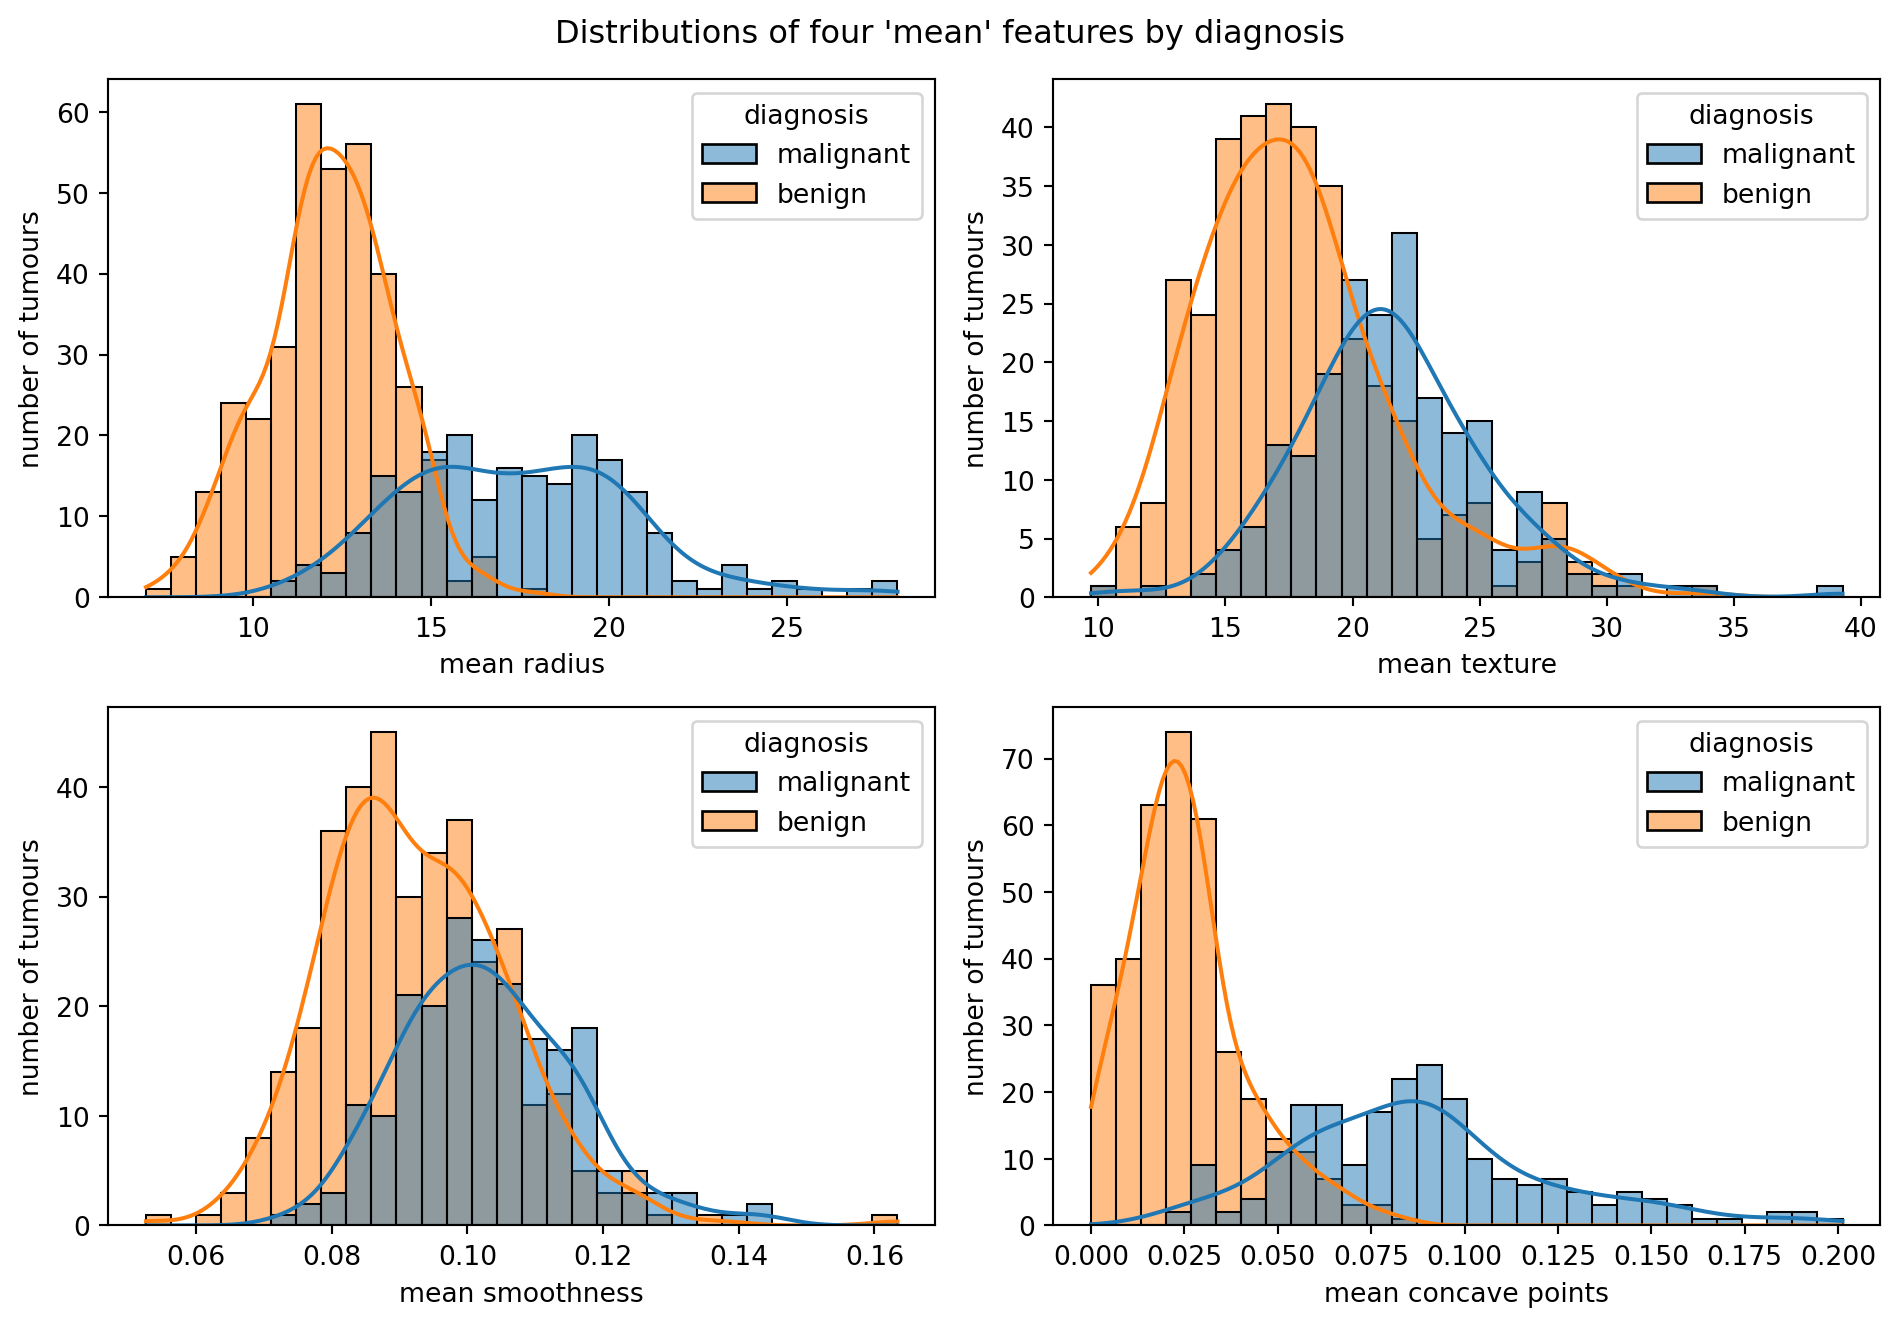

In [10]:
#| fig-alt: "A two-by-two grid of histograms with density curves for mean radius, mean texture, mean concave points and mean smoothness, each split by diagnosis; malignant distributions sit to the right of benign ones, most clearly for radius and concave points."
# Task 4: 2x2 grid of sns.histplot(..., hue="diagnosis", kde=True) for the four features below
four = ["mean radius", "mean texture", "mean smoothness", "mean concave points"]

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, col in zip(axes.flat, four):
    sns.histplot(data=df, x=col, hue="diagnosis", kde=True, bins=30, ax=ax)
    ax.set(ylabel="number of tumours")
fig.suptitle("Distributions of four 'mean' features by diagnosis")
fig.tight_layout()
plt.show()

In [11]:
assert set(four) <= set(df.columns), "one of the four feature names is misspelt"
print("✅ Task 4: four histograms drawn")

✅ Task 4: four histograms drawn


`mean concave points` and `mean radius` separate the classes well: the malignant distribution sits clearly to the
right, with limited overlap. `mean smoothness` and especially `mean texture` overlap heavily. Keep this
impression; Task 8 puts a number on it.

## Task 5: box plots

Box plots show the same comparison more compactly. Draw a 1 × 3 row of box plots of `mean radius`,
`mean area` and `mean concave points` by diagnosis (`sns.boxplot(data=df, x="diagnosis", y=..., hue="diagnosis",
legend=False, ax=ax)`). Then compute `medians`: the median of `mean radius` per diagnosis, via `groupby`.

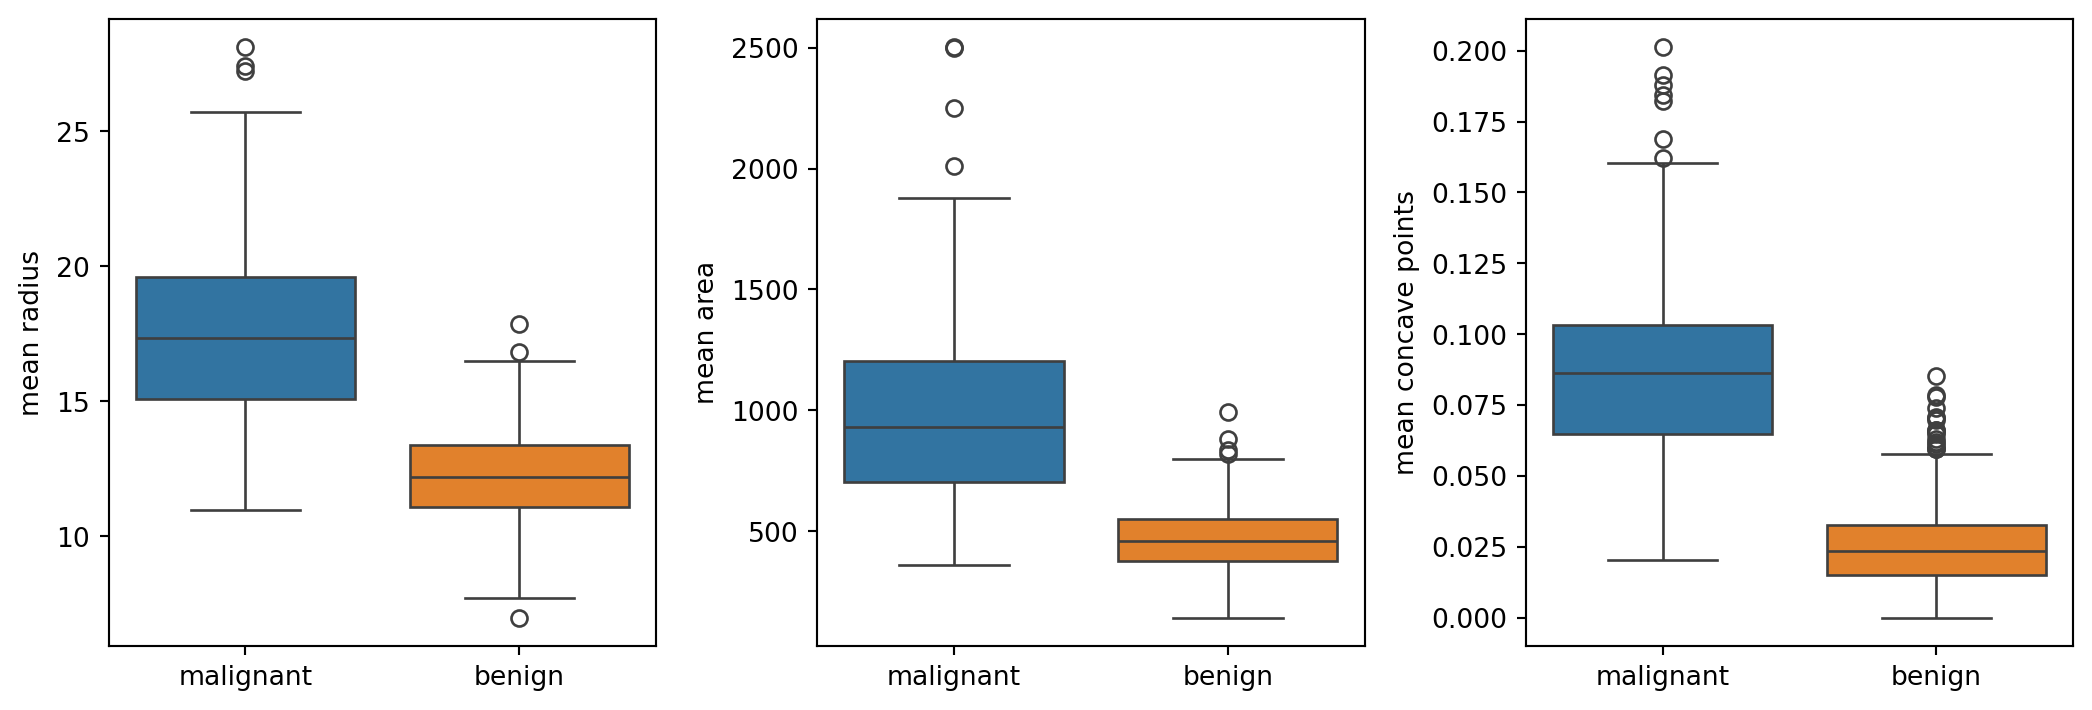

diagnosis
benign       12.200
malignant    17.325
Name: mean radius, dtype: float64

In [12]:
#| fig-alt: "Three box plots by diagnosis for mean radius, mean concave points and mean texture; malignant tumours have higher medians and wider spread in all three."
# Task 5: three box plots by diagnosis, then medians = df.groupby("diagnosis")["mean radius"].median()
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for ax, col in zip(axes, ["mean radius", "mean area", "mean concave points"]):
    sns.boxplot(data=df, x="diagnosis", y=col, hue="diagnosis", legend=False, ax=ax)
    ax.set(xlabel="")
fig.tight_layout()
plt.show()

medians = df.groupby("diagnosis")["mean radius"].median()
medians

In [13]:
assert medians["malignant"] > medians["benign"], "malignant tumours should have the larger median radius"
assert abs(medians["malignant"] - 17.3) < 0.2 and abs(medians["benign"] - 12.2) < 0.2, "unexpected medians; check the groupby"
print(f"✅ Task 5: median mean radius is {medians['malignant']:.1f} (malignant) vs {medians['benign']:.1f} (benign)")

✅ Task 5: median mean radius is 17.3 (malignant) vs 12.2 (benign)


Malignant nuclei are larger (median radius about 17 versus 12) and far more irregular (concave points). Note the
outliers above the benign boxes: a few benign tumours have nuclei as large as a typical malignant one, which is
where any classifier will make mistakes.

## Task 6: correlation heatmap

Compute the Pearson correlation matrix of the ten `mean_features` and store it in `corr`. Draw it with
`sns.heatmap(corr, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="vlag")`. Shorten the tick labels by stripping
the `"mean "` prefix (`corr.rename(columns=..., index=...)` or set the tick labels on the axes).
Which pairs of features are nearly interchangeable?

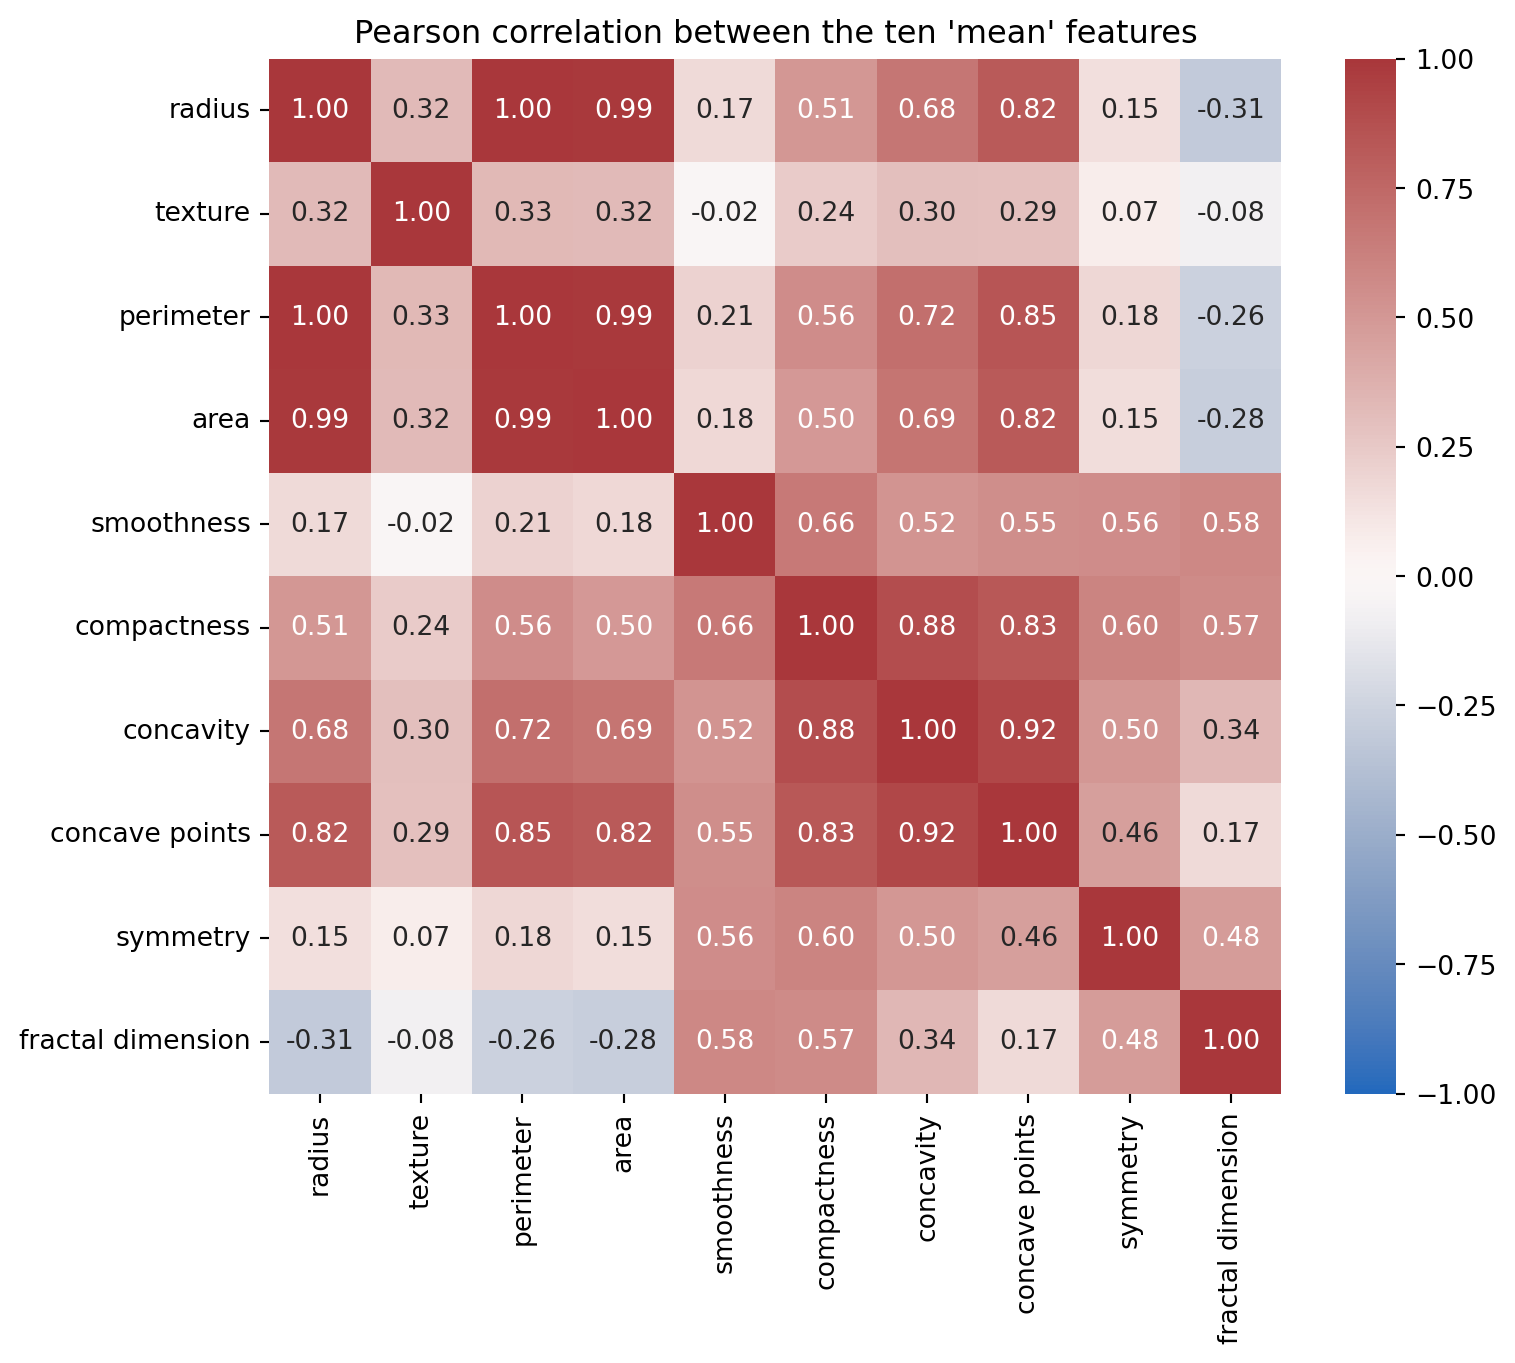

In [14]:
#| fig-alt: "A ten-by-ten heatmap of Pearson correlations between the mean features, with values printed in each cell; radius, perimeter and area correlate at 0.99 or above."
# Task 6: corr = correlation matrix of df[mean_features]; heatmap with annot=True, fmt=".2f", vmin=-1, vmax=1
corr = df[mean_features].corr()
short = {c: c.replace("mean ", "") for c in mean_features}

fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(corr.rename(columns=short, index=short), annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="vlag", ax=ax)
ax.set(title="Pearson correlation between the ten 'mean' features")
plt.show()

In [15]:
assert corr.shape == (10, 10), "corr should be a 10 x 10 matrix of the 'mean' features"
assert abs(corr.loc["mean radius", "mean perimeter"] - 1.0) < 0.01, "radius and perimeter should correlate almost perfectly"
print(f"✅ Task 6: radius–perimeter r = {corr.loc['mean radius', 'mean perimeter']:.3f}, radius–area r = {corr.loc['mean radius', 'mean area']:.3f}")

✅ Task 6: radius–perimeter r = 0.998, radius–area r = 0.987


Radius, perimeter and area are three measurements of one thing, size, and correlate at 0.99 or above. Compactness,
concavity and concave points form a second block (0.8 to 0.9). A model fed all ten features is really being fed
about four independent pieces of information; the rest is repetition.

## Task 7: pairplot

Draw a pairplot of `mean radius`, `mean texture`, `mean smoothness` and `mean concave points`, coloured by
`diagnosis`, with `corner=True`. (`sns.pairplot` is a figure-level function: do not call `plt.subplots()` first.)
Which *pair* of features separates the classes best?

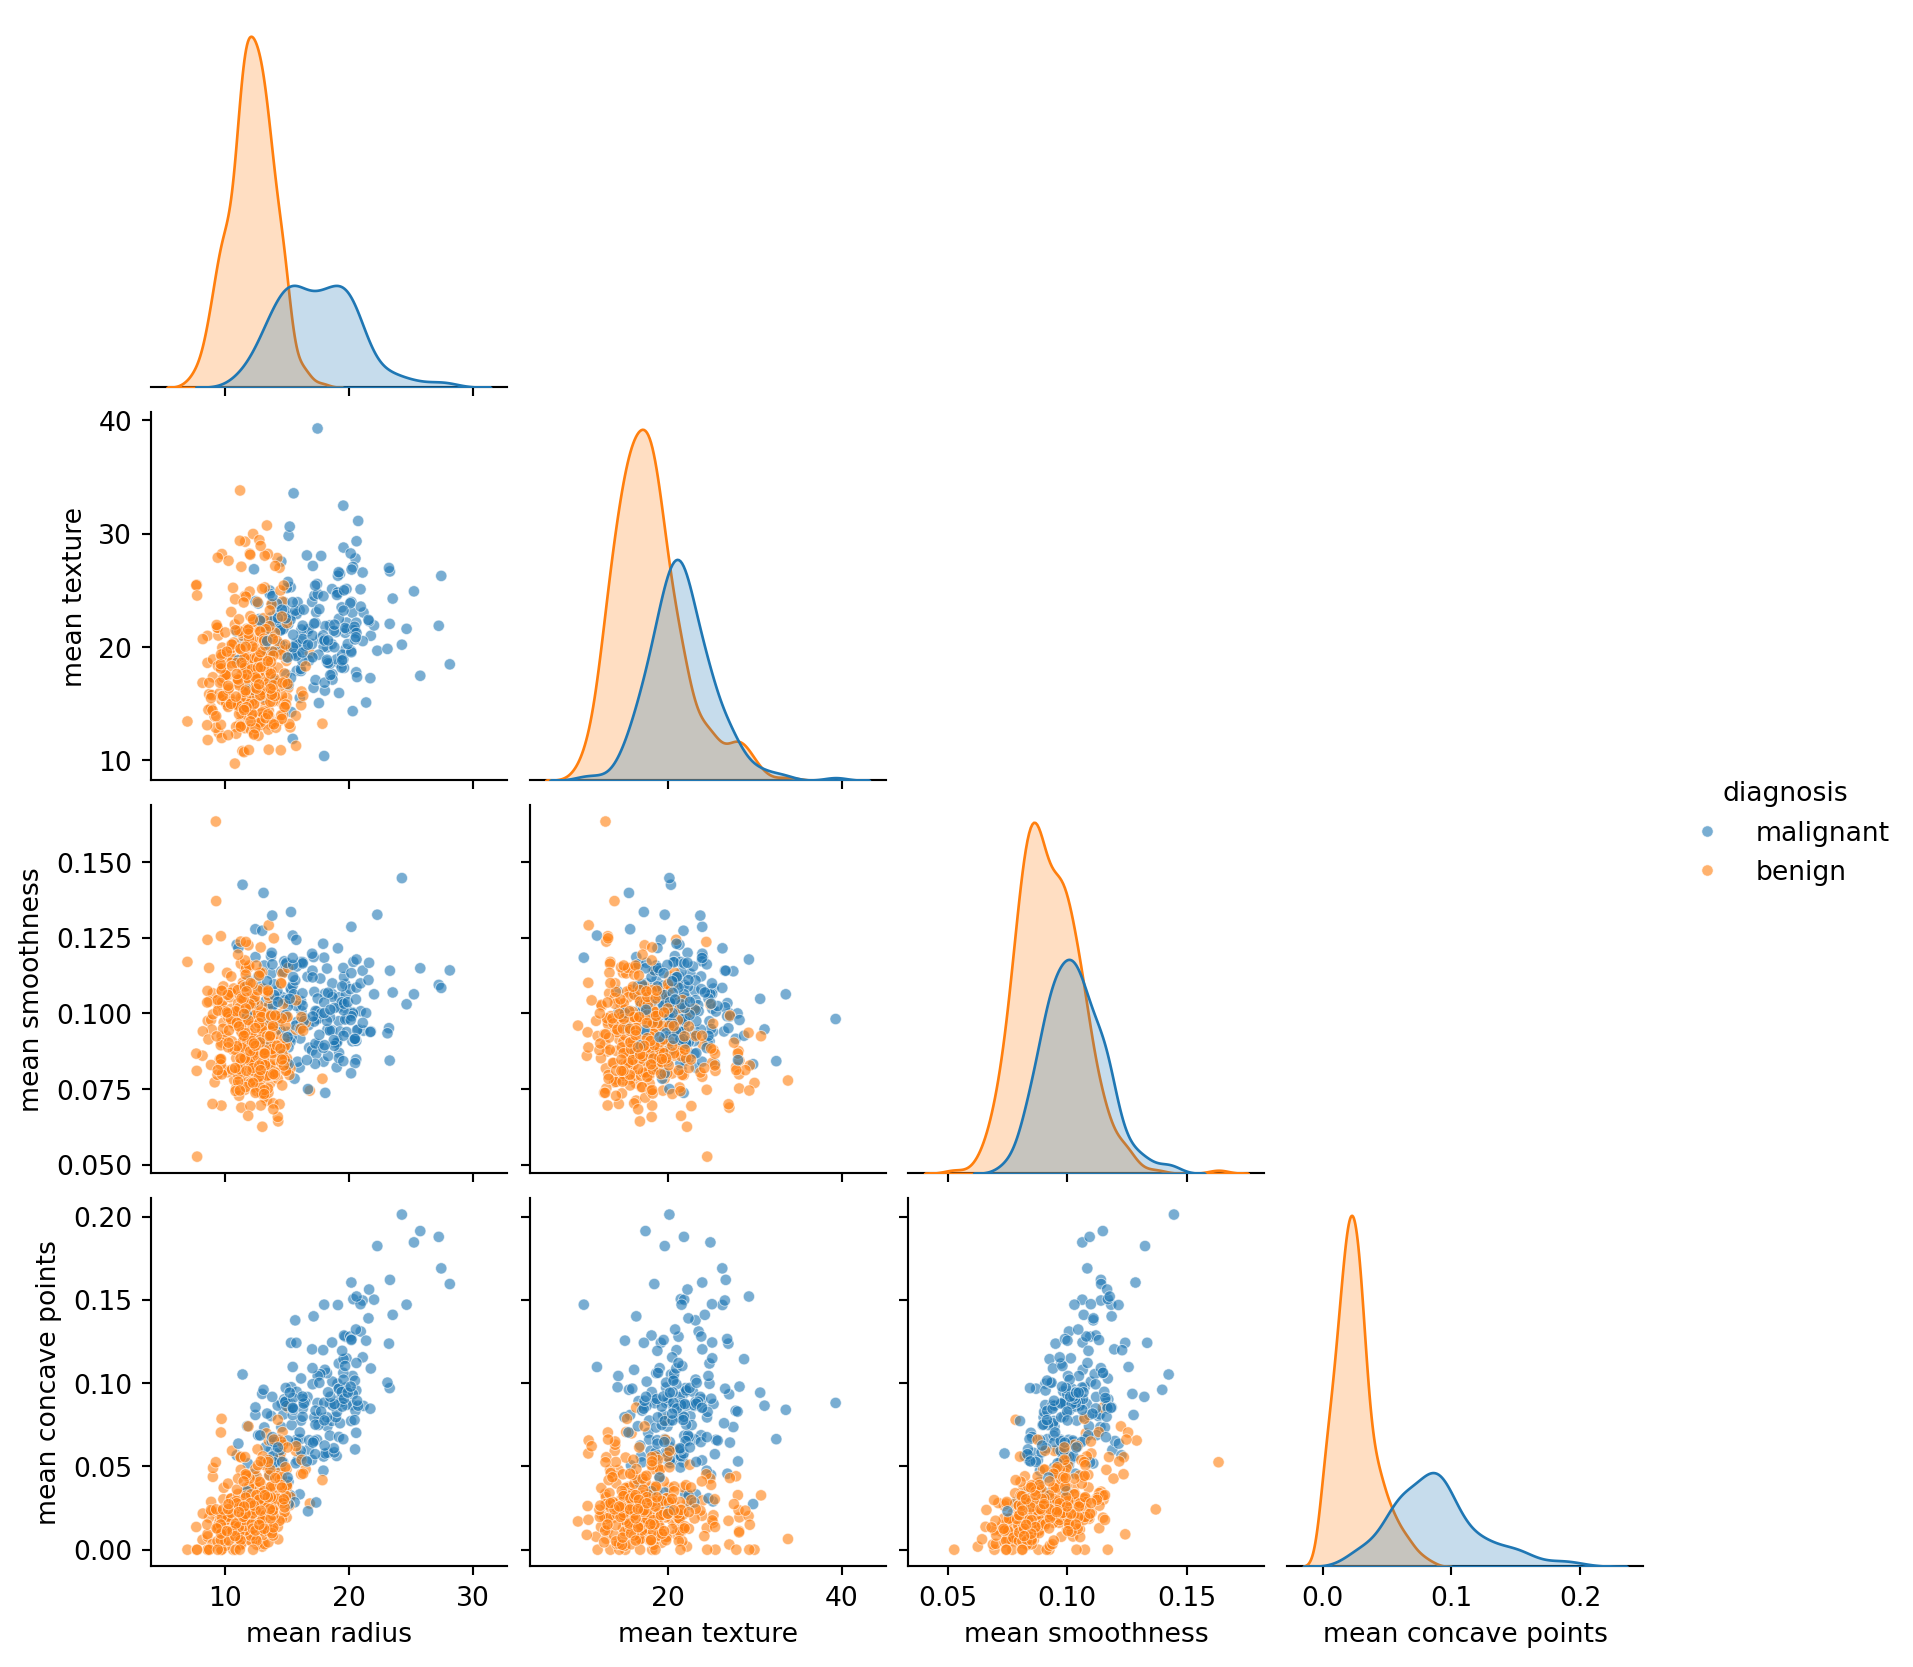

In [16]:
#| fig-alt: "A lower-triangular pairplot of four mean features coloured by diagnosis, with density curves on the diagonal; benign tumours cluster at small radius and few concave points."
# Task 7: sns.pairplot of df[four + ["diagnosis"]], hue="diagnosis", corner=True
sns.pairplot(df[four + ["diagnosis"]], hue="diagnosis", corner=True, height=2.2, plot_kws={"alpha": 0.6, "s": 18})
plt.show()

In [17]:
print("✅ Task 7: pairplot drawn (if the previous cell shows a triangular grid of 10 panels)")

✅ Task 7: pairplot drawn (if the previous cell shows a triangular grid of 10 panels)


`mean radius` against `mean concave points` gives the cleanest split: the benign tumours bunch in the bottom-left
corner (small, smooth nuclei) and the malignant ones spread up and to the right. Combining two features separates
more than either alone, which is the whole idea behind the classifiers in Chapter 2.

## Task 8: which features separate the classes best?

Eyeballing histograms does not scale to 30 features. A simple score for how well a feature separates two groups is
the **standardised mean difference**: the difference between the group means divided by the pooled standard
deviation,

$$d = \frac{|\bar{x}_{\text{malignant}} - \bar{x}_{\text{benign}}|}{\sqrt{(s^2_{\text{malignant}} + s^2_{\text{benign}}) / 2}} .$$

A $d$ of 0 means the groups have the same mean; a $d$ above 2 means they barely overlap. Compute $d$ for all
30 numeric features (every column except `target` and `diagnosis`), store the result as a Series `separation`
sorted from largest to smallest, and print the top five.

In [18]:
# Task 8: separation = standardised mean difference of every feature between the two classes, sorted descending
features = [c for c in df.columns if c not in ("target", "diagnosis")]
grouped = df.groupby("diagnosis")[features]
means, stds = grouped.mean(), grouped.std()
pooled = np.sqrt((stds.loc["malignant"] ** 2 + stds.loc["benign"] ** 2) / 2)
separation = ((means.loc["malignant"] - means.loc["benign"]).abs() / pooled).sort_values(ascending=False)
separation.head(5).round(2)

worst concave points    2.60
worst perimeter         2.37
mean concave points     2.33
worst radius            2.32
mean perimeter          2.12
dtype: float64

In [19]:
assert len(separation) == 30, f"expected one score per feature (30), got {len(separation)}"
assert separation.index[0] in ("worst concave points", "worst perimeter", "mean concave points", "worst radius", "worst area"), "unexpected top feature; check the formula"
assert separation.is_monotonic_decreasing, "sort the scores from largest to smallest"
print("✅ Task 8: top three features:", ", ".join(separation.index[:3]))

✅ Task 8: top three features: worst concave points, worst perimeter, mean concave points


The top of the list is dominated by the `worst ...` versions of concave points, perimeter, radius and area, and by
`mean concave points`: the most irregular and largest nuclei in the image are the most telling. At the bottom sit
the `... error` features and `mean fractal dimension`, which separate the classes hardly at all.

A quick cross-check with a different score: the point-biserial correlation between each feature and the 0/1 target
is just `df[features].corrwith(df["target"])`. Its ranking should agree with yours at the top.

In [20]:
# Cross-check (nothing to write): correlation of each feature with the 0/1 target, largest magnitude first
df[features].corrwith(df["target"]).abs().sort_values(ascending=False).head(5).round(3)

worst concave points    0.794
worst perimeter         0.783
mean concave points     0.777
worst radius            0.776
mean perimeter          0.743
dtype: float64

## Task 9: a short written summary

Edit the markdown cell below (double-click it) and replace each bullet with one or two sentences of your own.
A good EDA summary is short, concrete and names the features it talks about.

- **Size and balance:** how many samples, how many features, how balanced are the classes, anything missing?
- **Scales:** are the features comparable in magnitude, or do some dwarf others?
- **Redundancy:** which features say the same thing?
- **Signal:** which three features separate malignant from benign best, and how cleanly?
- **Caution:** where would you expect a classifier to make mistakes?

**Example summary (one of many good answers)**

- *Size and balance:* 569 tumours and 30 numeric features, no missing values; 357 benign (63%) and 212 malignant,
  so a mild imbalance that any accuracy figure has to be read against.
- *Scales:* areas run into the thousands while smoothness and fractal dimension are below 0.2; features must be
  scaled before any distance-based model.
- *Redundancy:* radius, perimeter and area are one measurement in three guises (r ≥ 0.99); compactness, concavity
  and concave points form a second block.
- *Signal:* `worst concave points`, `worst perimeter` and `mean concave points` separate the classes with $d$ above 2;
  the irregularity of the nucleus outline is the strongest single signal.
- *Caution:* a few benign tumours have nuclei as large as malignant ones, and texture and symmetry overlap almost
  completely; errors will cluster among large-but-smooth benign tumours and small-but-irregular malignant ones.

## Reflection questions

1. The dataset is 63% benign. If a model predicted "benign" for every tumour, what would its accuracy be, and what
   would be wrong with reporting that number? Which single number from this lab would you quote instead?
2. Radius, perimeter and area correlate at 0.99 or above. Would you remove two of the three before training a
   model? What might you lose, and what might you gain?
3. The standardised mean difference in Task 8 only sees the *means* of each class. Describe a feature that could
   separate the classes well yet score a low $d$, and which plot from this lab would reveal it.